# SPD Brain Connectomes — MLSP/COBRE Results

**Goal.** Compare four 2-D representations of the same 86 brain-connectome subjects. PCA is Euclidean; tangent PCA first maps SPD matrices to a linear tangent space; the autoencoder and MIAF learn nonlinear embeddings.

In [1]:
# Imports and reproducibility
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from torch.utils.data import DataLoader, TensorDataset

warnings.filterwarnings("ignore")
np.random.seed(42)
torch.manual_seed(42)
plt.rcParams["figure.dpi"] = 130

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
TRAIN = ROOT / "train"
FIGURES = ROOT / "figures"
FIGURES.mkdir(exist_ok=True)
print(ROOT)


C:\Users\Globaltech\Reduction-des-matrices-SPD


In [2]:
# Data: 86 subjects, 378 FNC values, labels
fnc = pd.read_csv(TRAIN / "train_FNC.csv")
labels_df = pd.read_csv(TRAIN / "train_labels.csv")
assert np.array_equal(fnc["Id"].to_numpy(), labels_df["Id"].to_numpy())

ids = fnc["Id"].to_numpy()
X = fnc.drop(columns=["Id"]).to_numpy(dtype=np.float64)
y = labels_df["Class"].to_numpy(dtype=np.int64)
rows, cols = np.triu_indices(28, k=1)

print(f"subjects={len(y)}, features={X.shape[1]}, classes={dict(zip(*np.unique(y, return_counts=True)))}")


subjects=86, features=378, classes={np.int64(0): np.int64(46), np.int64(1): np.int64(40)}


In [3]:
# SPD construction and tangent coordinates
def vectors_to_symmetric(vectors):
    matrices = np.zeros((len(vectors), 28, 28), dtype=np.float64)
    matrices[:, rows, cols] = vectors
    matrices[:, cols, rows] = vectors
    return matrices


def matrix_exp_symmetric(matrix):
    eigenvalues, eigenvectors = np.linalg.eigh(matrix)
    return (eigenvectors * np.exp(eigenvalues)) @ eigenvectors.T


def matrix_log_spd(matrix):
    eigenvalues, eigenvectors = np.linalg.eigh(matrix)
    if np.any(eigenvalues <= 0):
        raise ValueError("Matrix is not SPD.")
    return (eigenvectors * np.log(eigenvalues)) @ eigenvectors.T


symmetric = vectors_to_symmetric(X)
spd = np.stack([matrix_exp_symmetric(matrix) for matrix in symmetric])
spd_eigenvalues = np.linalg.eigvalsh(spd)
log_spd = np.stack([matrix_log_spd(matrix) for matrix in spd])
tangent = log_spd[:, rows, cols].astype(np.float32)

assert np.all(spd_eigenvalues > 0)
print(f"SPD shape={spd.shape}, tangent shape={tangent.shape}")
print(f"minimum eigenvalue={spd_eigenvalues.min():.6f}")


SPD shape=(86, 28, 28), tangent shape=(86, 378)
minimum eigenvalue=0.368715


### Why the exponential gives SPD matrices

For each symmetric connectivity matrix, use the eigendecomposition
$$
A = Q \Lambda Q^{\mathsf T},
$$
where \(Q\) is orthogonal and
\(\Lambda=\operatorname{diag}(\lambda_1,\ldots,\lambda_{28})\).
The matrix exponential is
$$
S=\exp(A)
  =Q\,\operatorname{diag}\!\left(e^{\lambda_1},\ldots,e^{\lambda_{28}}\right)
   Q^{\mathsf T}.
$$
Because \(e^{\lambda_i}>0\) for every \(i\), all eigenvalues of \(S\) are
strictly positive. Therefore \(S=S^{\mathsf T}\succ0\), so \(S\) is SPD.
The inverse spectral map is
$$
\log(S)=Q\,\operatorname{diag}\!\left(\log \mu_1,\ldots,\log \mu_{28}\right)
Q^{\mathsf T},
$$
where \(\mu_i>0\) are the eigenvalues of \(S\). These log-coordinates are
used by tangent PCA.


In [4]:
# PCA and tangent PCA
def scale_pca(features):
    scaled = StandardScaler().fit_transform(features)
    return PCA(n_components=2, random_state=42).fit_transform(scaled)


Z_pca = scale_pca(spd.reshape(len(spd), -1))
Z_tangent_pca = scale_pca(tangent)


### PCA versus tangent PCA

**Euclidean PCA.** Flatten each SPD matrix \(S_i\) into a vector
\(\operatorname{vec}(S_i)\), standardize the features, and find two
directions of maximum variance:
$$
Z_{\mathrm{PCA}}
  =\operatorname{PCA}_2\!\left(
    \operatorname{StandardScaler}\!\left[
      \operatorname{vec}(S_1),\ldots,\operatorname{vec}(S_{86})
    \right]\right).
$$

**Tangent PCA.** First map each SPD matrix to the logarithm, retain its
strict upper triangle \(u_i=\operatorname{upper}(\log S_i)\), and then
apply the same two-component PCA:
$$
Z_{\mathrm{TPCA}}
  =\operatorname{PCA}_2\!\left(
    \operatorname{StandardScaler}\!\left[
      u_1,\ldots,u_{86}
    \right]\right).
$$
The logarithm converts the curved SPD space into a locally Euclidean
tangent representation before dimensionality reduction.

In [5]:
# Autoencoder
class Autoencoder(nn.Module):
    def __init__(self, input_dim, hidden=(189, 47, 11), latent_dim=2):
        super().__init__()
        encoder = []
        previous = input_dim
        for width in hidden:
            encoder += [nn.Linear(previous, width), nn.ReLU()]
            previous = width
        encoder.append(nn.Linear(previous, latent_dim))
        decoder = []
        previous = latent_dim
        for width in reversed(hidden):
            decoder += [nn.Linear(previous, width), nn.ReLU()]
            previous = width
        decoder.append(nn.Linear(previous, input_dim))
        self.encoder = nn.Sequential(*encoder)
        self.decoder = nn.Sequential(*decoder)

    def forward(self, features):
        latent = self.encoder(features)
        return self.decoder(latent), latent


def train_autoencoder(features, epochs=100):
    model = Autoencoder(features.shape[1])
    data = torch.from_numpy(features.astype(np.float32))
    loader = DataLoader(TensorDataset(data), batch_size=32, shuffle=True)
    optimizer = optim.AdamW(model.parameters(), lr=1e-3)
    criterion = nn.MSELoss()
    losses = []
    for _ in range(epochs):
        total = 0.0
        for (batch,) in loader:
            optimizer.zero_grad()
            reconstruction, _ = model(batch)
            loss = criterion(reconstruction, batch)
            loss.backward()
            optimizer.step()
            total += loss.item() * len(batch)
        losses.append(total / len(features))
    return model, losses


ae_model, ae_losses = train_autoencoder(tangent)
with torch.no_grad():
    Z_autoencoder = ae_model.encoder(torch.from_numpy(tangent)).numpy()


In [6]:
# MIAF
def group_features(features, bins=20, threshold=0.5):
    histograms = []
    for feature in features.T:
        counts, _ = np.histogram(feature, bins=bins)
        counts = counts.astype(float) + 1e-12
        histograms.append(counts / counts.sum())
    histograms = np.asarray(histograms)
    distances = np.zeros((len(histograms), len(histograms)))
    for i in range(len(histograms)):
        for j in range(i + 1, len(histograms)):
            p, q = histograms[i], histograms[j]
            distances[i, j] = distances[j, i] = 0.5 * (
                np.sum(p * np.log(p / q)) + np.sum(q * np.log(q / p))
            )
    from scipy.cluster.hierarchy import fcluster, linkage
    from scipy.spatial.distance import squareform
    cluster_ids = fcluster(
        linkage(squareform(distances, checks=False), method="average"),
        threshold,
        criterion="distance",
    )
    groups = {}
    for index, cluster_id in enumerate(cluster_ids):
        groups.setdefault(int(cluster_id), []).append(index)
    return [np.asarray(group, dtype=np.int64) for group in groups.values()]


class MIAF(nn.Module):
    def __init__(self, groups, latent_dim=2):
        super().__init__()
        self.groups = groups
        self.encoders = nn.ModuleList([
            nn.Sequential(nn.Linear(len(group), 16), nn.ReLU(), nn.Linear(16, 16), nn.ReLU())
            for group in groups
        ])
        encoded_dim = 16 * len(groups)
        self.selector = nn.Linear(encoded_dim, latent_dim)
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 128), nn.ReLU(),
            nn.Linear(128, 64), nn.ReLU(),
            nn.Linear(64, sum(len(group) for group in groups)),
        )

    def forward(self, grouped):
        encoded = torch.cat([encoder(part) for encoder, part in zip(self.encoders, grouped)], dim=1)
        latent = torch.relu(self.selector(encoded))
        return self.decoder(latent), latent


def train_miaf(features, groups, epochs=100):
    model = MIAF(groups)
    grouped = [torch.from_numpy(features[:, group]) for group in groups]
    optimizer = optim.AdamW(model.parameters(), lr=1e-3)
    criterion = nn.MSELoss()
    for _ in range(epochs):
        permutation = torch.randperm(len(features))
        for start in range(0, len(features), 32):
            indices = permutation[start:start + 32]
            batch = [part[indices] for part in grouped]
            target = torch.cat(batch, dim=1)
            optimizer.zero_grad()
            reconstruction, _ = model(batch)
            loss = criterion(reconstruction, target)
            loss = loss + torch.norm(model.selector.weight, p=2, dim=1).sum()
            loss.backward()
            optimizer.step()
    return model


groups = group_features(tangent)
miaf_model = train_miaf(tangent, groups)
with torch.no_grad():
    grouped = [torch.from_numpy(tangent[:, group]) for group in groups]
    _, Z_miaf = miaf_model(grouped)
    Z_miaf = Z_miaf.numpy()


In [7]:
# Repeated 80/20 evaluation
embeddings = {
    "PCA": Z_pca,
    "Tangent PCA": Z_tangent_pca,
    "Autoencoder": Z_autoencoder,
    "MIAF": Z_miaf,
}
classifiers = {
    "kNN": KNeighborsClassifier(n_neighbors=5),
    "Logistic": LogisticRegression(max_iter=1000, random_state=42),
    "SVM": SVC(kernel="rbf", random_state=42),
    "Random forest": RandomForestClassifier(n_estimators=100, random_state=42),
}

records = []
for reducer, embedding in embeddings.items():
    for classifier_name, classifier_template in classifiers.items():
        scores = []
        for seed in range(10):
            train_idx, test_idx = train_test_split(
                np.arange(len(y)), test_size=0.2, random_state=seed, stratify=y
            )
            classifier = classifier_template
            classifier.fit(embedding[train_idx], y[train_idx])
            scores.append(accuracy_score(y[test_idx], classifier.predict(embedding[test_idx])))
        records.append((reducer, classifier_name, np.mean(scores), np.std(scores)))

results = pd.DataFrame(records, columns=["Reducer", "Classifier", "Mean accuracy", "Std"])
results


,Reducer,Classifier,Mean accuracy,Std
0,PCA,kNN,0.561111,0.130171
1,PCA,Logistic,0.494444,0.080316
2,PCA,SVM,0.550000,0.016667
3,PCA,Random forest,0.511111,0.130998
4,Tangent PCA,kNN,0.688889,0.083148
5,Tangent PCA,Logistic,0.677778,0.101835
6,Tangent PCA,SVM,0.622222,0.085346
7,Tangent PCA,Random forest,0.538889,0.074742
8,Autoencoder,kNN,0.655556,0.135628
9,Autoencoder,Logistic,0.627778,0.105556


### Evaluation

Each method is reduced to two dimensions, then evaluated on the same ten
stratified 80/20 splits. The table reports mean accuracy and its standard
deviation across the ten validation splits:
$$
\operatorname{Accuracy}
  =\frac{\#\{\text{correct predictions}\}}
          {\#\{\text{test subjects}\}},
\qquad
\overline{a}=\frac{1}{10}\sum_{r=1}^{10}a_r.
$$

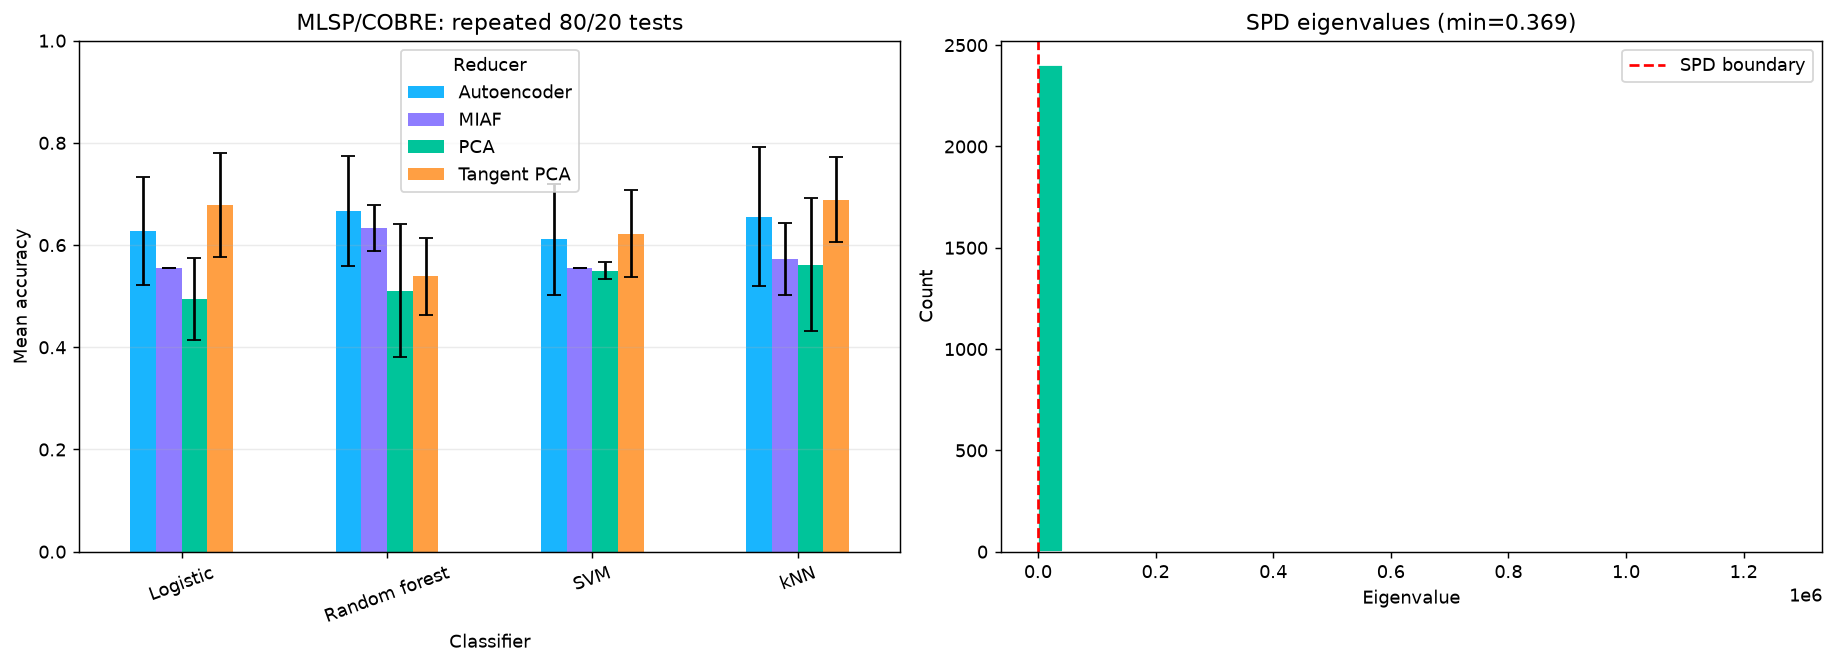

In [8]:
# Figures: results and SPD verification
fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
means = results.pivot(index="Classifier", columns="Reducer", values="Mean accuracy")
errors = results.pivot(index="Classifier", columns="Reducer", values="Std")
means.plot.bar(yerr=errors, capsize=4, ax=axes[0], color=["#19b5fe", "#8e7dff", "#00c49a", "#ff9f43"])
axes[0].set_ylim(0, 1)
axes[0].set_ylabel("Mean accuracy")
axes[0].set_title("MLSP/COBRE: repeated 80/20 tests")
axes[0].tick_params(axis="x", rotation=20)
axes[0].grid(axis="y", alpha=0.25)
axes[0].legend(title="Reducer")

axes[1].hist(spd_eigenvalues.ravel(), bins=30, color="#00c49a", edgecolor="white")
axes[1].axvline(0, color="red", linestyle="--", label="SPD boundary")
axes[1].set_title(f"SPD eigenvalues (min={spd_eigenvalues.min():.3f})")
axes[1].set_xlabel("Eigenvalue")
axes[1].set_ylabel("Count")
axes[1].legend()
plt.show()


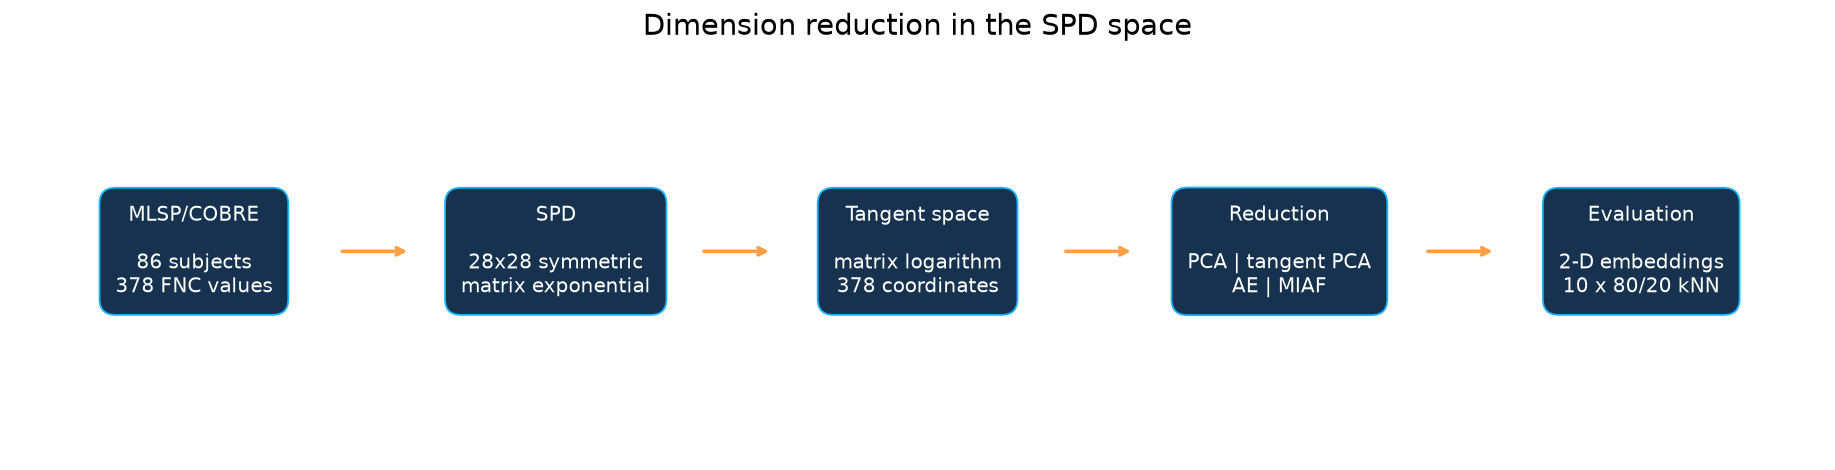

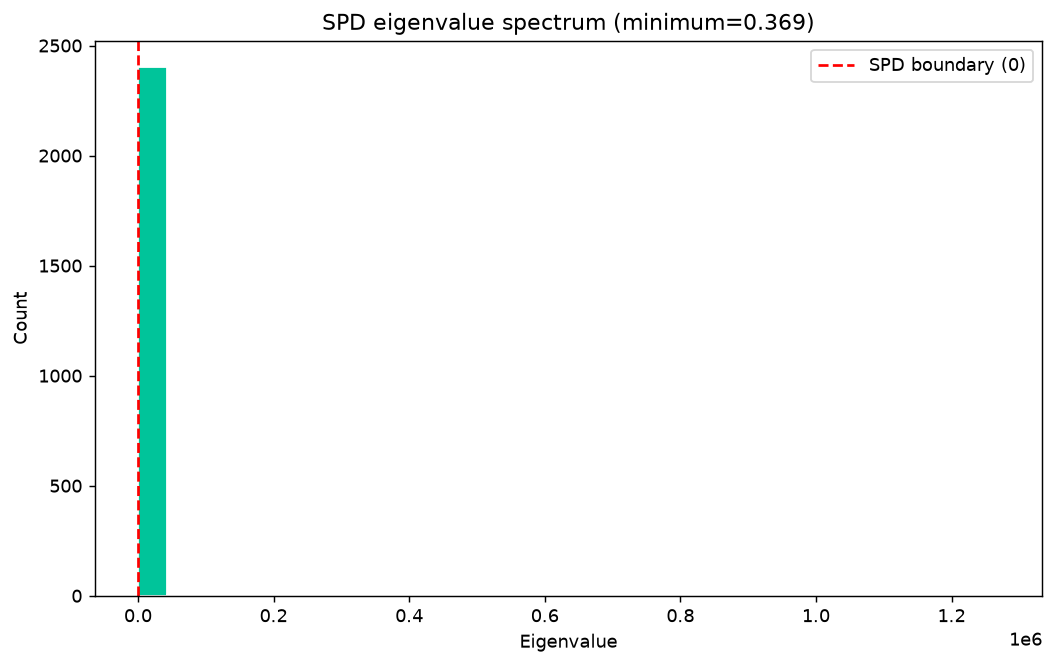

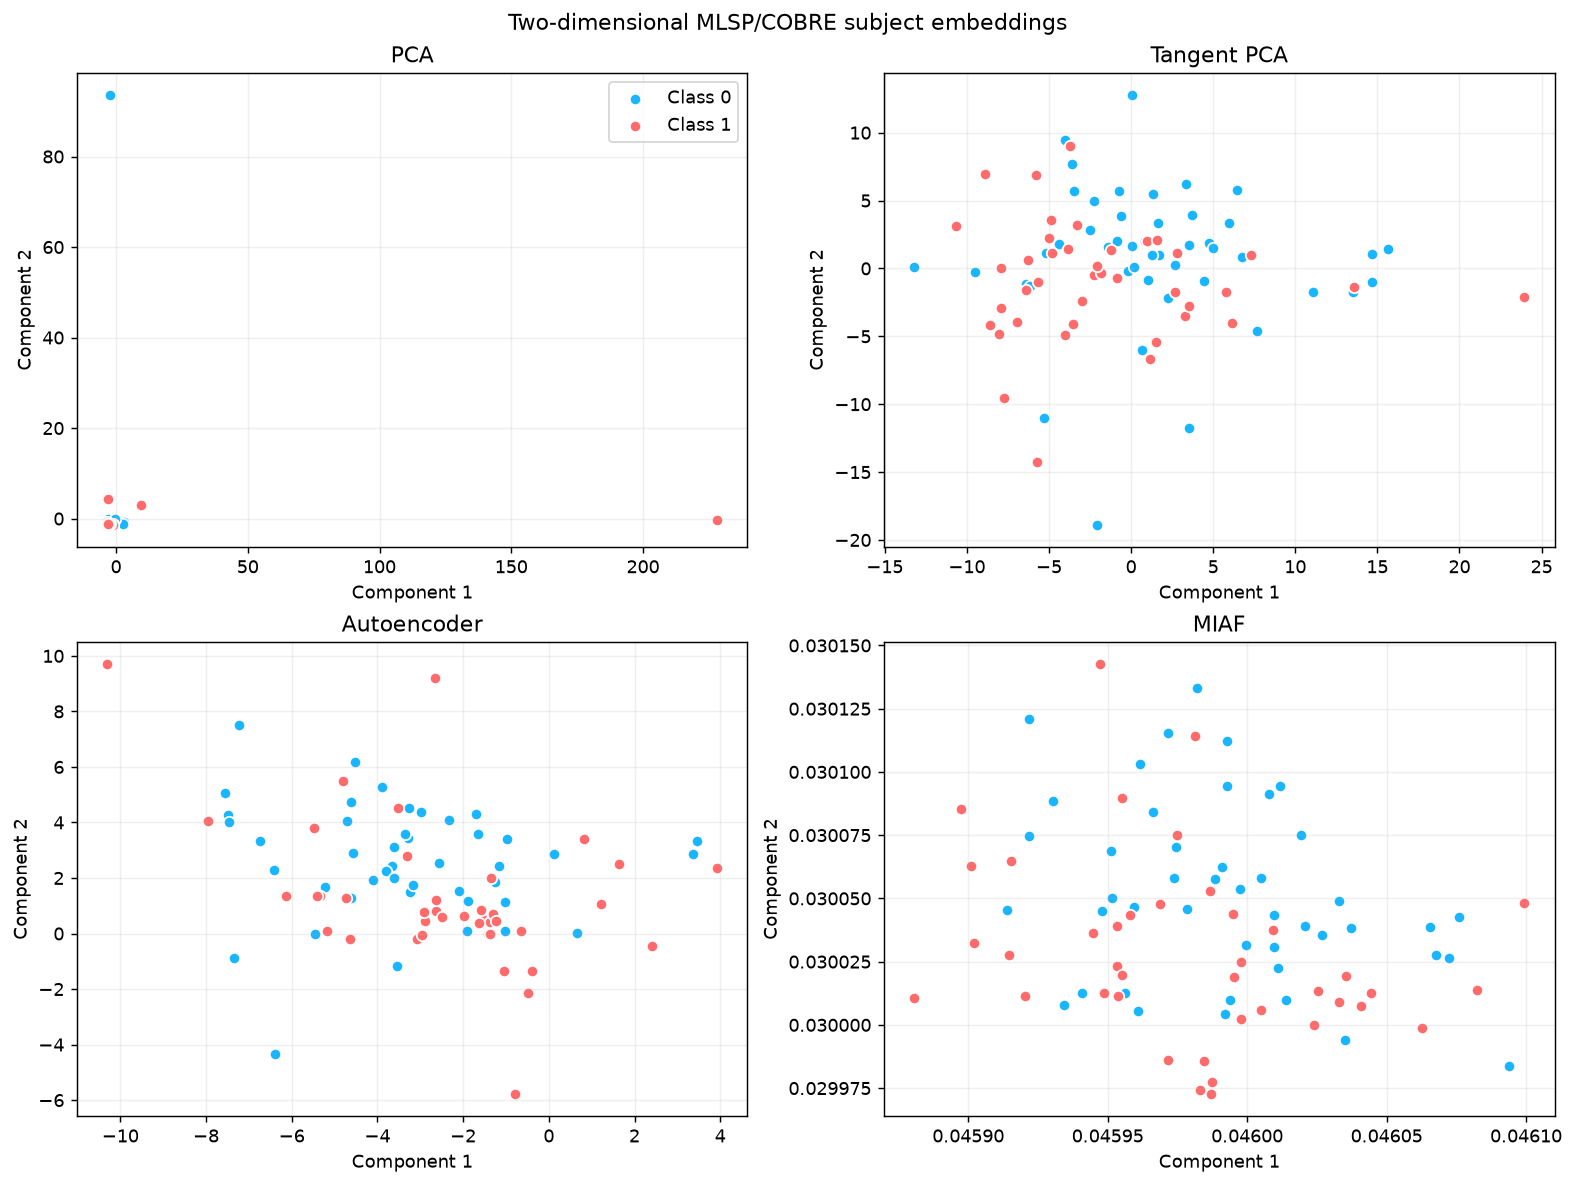

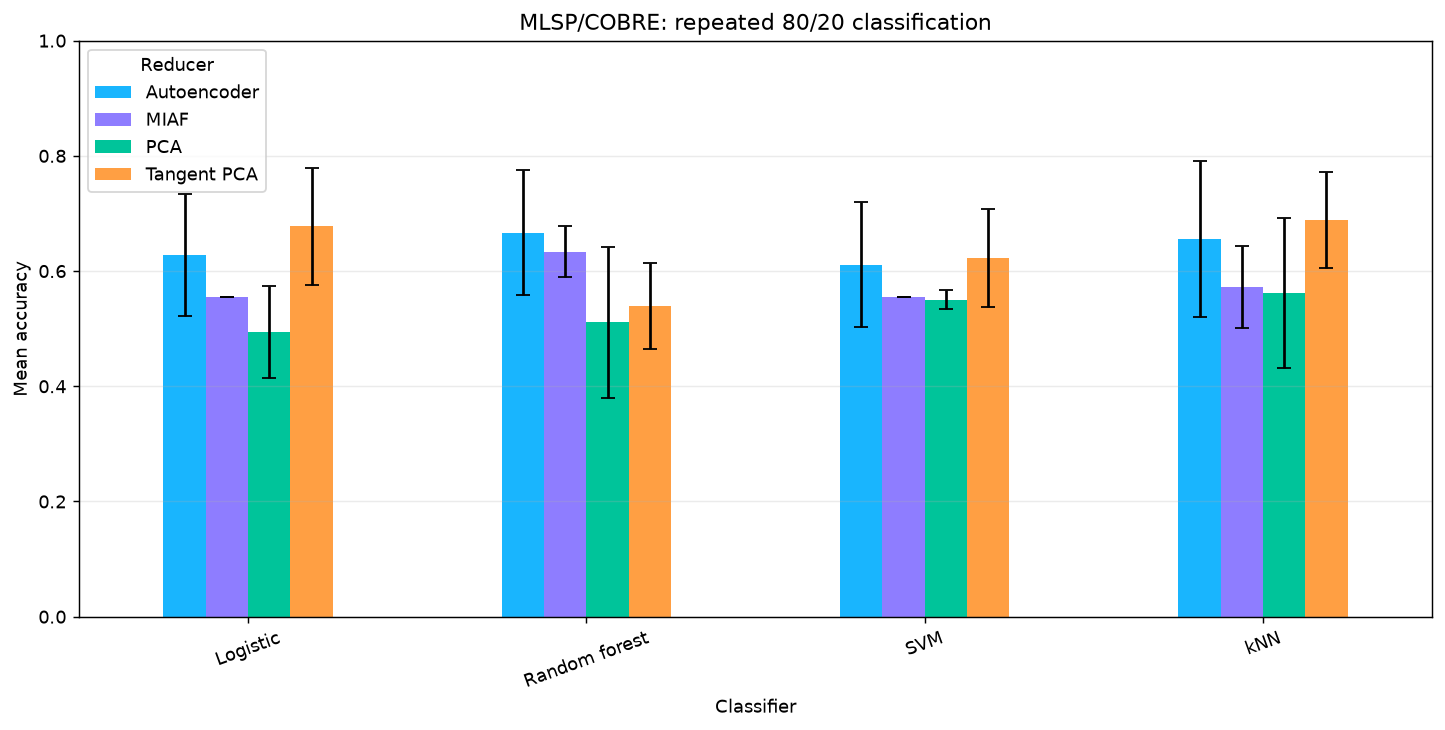

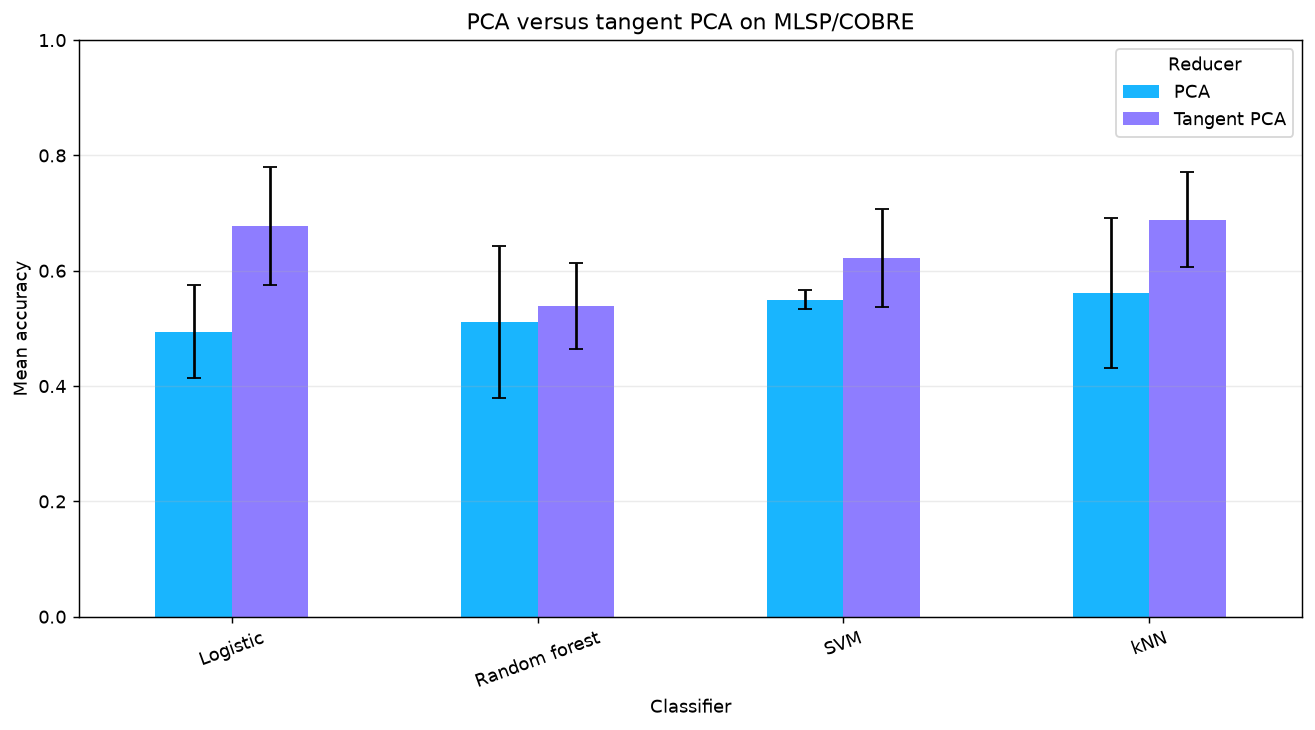

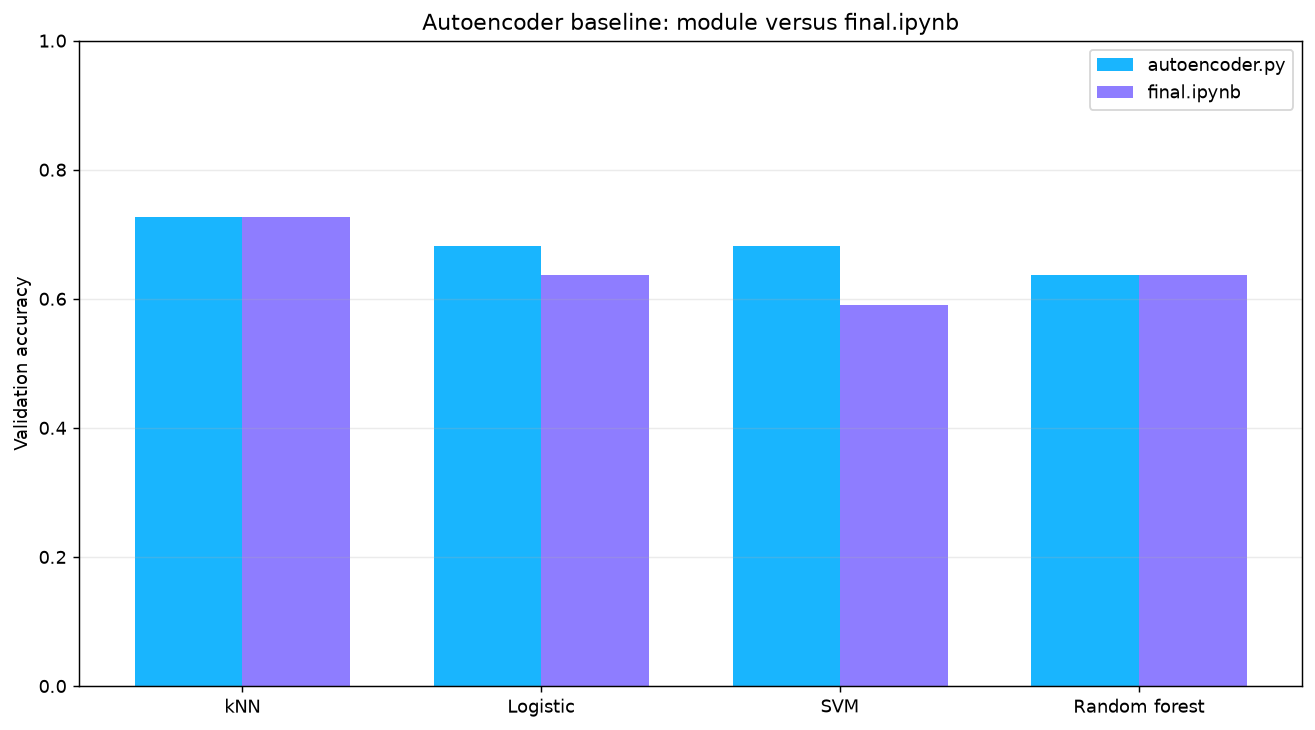

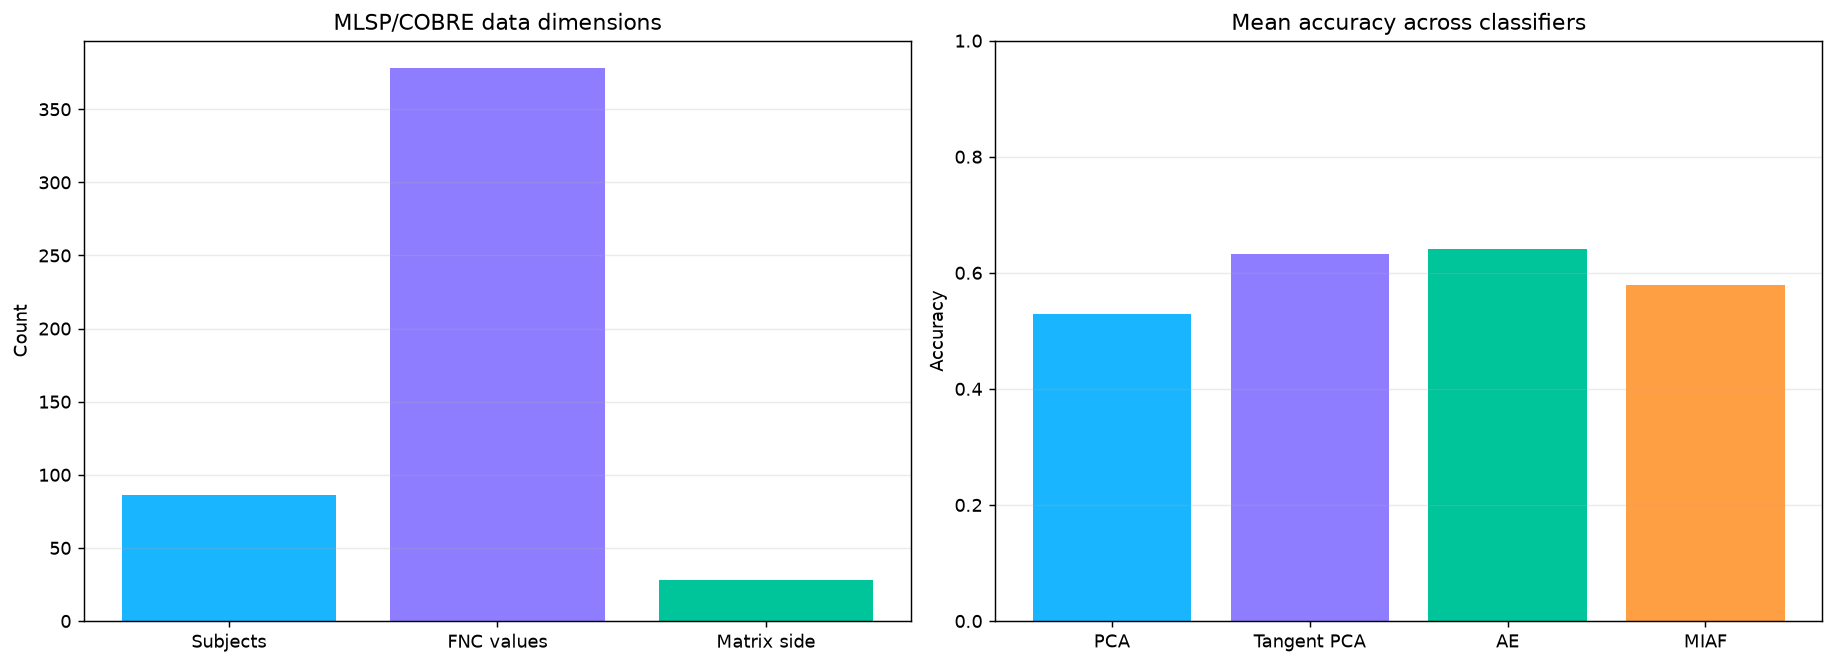

In [9]:
# Figures generated and integrated directly from notebook variables
from IPython.display import display

embeddings = {
    "PCA": Z_pca,
    "Tangent PCA": Z_tangent_pca,
    "Autoencoder": Z_autoencoder,
    "MIAF": Z_miaf,
}

# 1. Pipeline
fig, axis = plt.subplots(figsize=(14, 3.5), constrained_layout=True)
axis.axis("off")
stages = [
    ("MLSP/COBRE", "86 subjects\n378 FNC values"),
    ("SPD", "28x28 symmetric\nmatrix exponential"),
    ("Tangent space", "matrix logarithm\n378 coordinates"),
    ("Reduction", "PCA | tangent PCA\nAE | MIAF"),
    ("Evaluation", "2-D embeddings\n10 x 80/20 kNN"),
]
positions = np.linspace(0.1, 0.9, len(stages))
for i, (title, detail) in enumerate(stages):
    axis.text(positions[i], 0.5, f"{title}\n\n{detail}", ha="center", va="center",
              color="white", fontsize=11,
              bbox=dict(boxstyle="round,pad=0.8", facecolor="#16324f", edgecolor="#19b5fe"))
    if i < len(stages) - 1:
        axis.annotate("", xy=(positions[i + 1] - 0.08, 0.5),
                      xytext=(positions[i] + 0.08, 0.5),
                      arrowprops=dict(arrowstyle="->", color="#ff9f43", lw=2))
axis.set_title("Dimension reduction in the SPD space", fontsize=16)
display(fig)
fig.savefig(FIGURES / "01_pipeline.png", dpi=180, bbox_inches="tight")
plt.close(fig)

# 2. SPD eigenvalues
fig, axis = plt.subplots(figsize=(8, 5), constrained_layout=True)
axis.hist(spd_eigenvalues.ravel(), bins=30, color="#00c49a", edgecolor="white")
axis.axvline(0, color="red", linestyle="--", label="SPD boundary (0)")
axis.set_title(f"SPD eigenvalue spectrum (minimum={spd_eigenvalues.min():.3f})")
axis.set_xlabel("Eigenvalue")
axis.set_ylabel("Count")
axis.legend()
display(fig)
fig.savefig(FIGURES / "02_spd_eigenvalues.png", dpi=180, bbox_inches="tight")
plt.close(fig)

# 3. Four integrated 2-D embeddings
fig, axes = plt.subplots(2, 2, figsize=(12, 9), constrained_layout=True)
for axis, (name, embedding) in zip(axes.flat, embeddings.items()):
    for label, color in [(0, "#19b5fe"), (1, "#ff6b6b")]:
        mask = y == label
        axis.scatter(embedding[mask, 0], embedding[mask, 1], s=40,
                     color=color, label=f"Class {label}", edgecolors="white")
    axis.set_title(name)
    axis.set_xlabel("Component 1")
    axis.set_ylabel("Component 2")
    axis.grid(alpha=0.2)
axes.flat[0].legend()
fig.suptitle("Two-dimensional MLSP/COBRE subject embeddings")
display(fig)
fig.savefig(FIGURES / "03_subject_embeddings.png", dpi=180, bbox_inches="tight")
plt.close(fig)

# 4. Accuracy comparison for all four reductions
fig, axis = plt.subplots(figsize=(11, 5.5), constrained_layout=True)
accuracy_table = results.pivot(index="Classifier", columns="Reducer", values="Mean accuracy")
error_table = results.pivot(index="Classifier", columns="Reducer", values="Std")
accuracy_table.plot.bar(yerr=error_table, capsize=4, ax=axis,
                        color=["#19b5fe", "#8e7dff", "#00c49a", "#ff9f43"])
axis.set_ylim(0, 1)
axis.set_ylabel("Mean accuracy")
axis.set_title("MLSP/COBRE: repeated 80/20 classification")
axis.tick_params(axis="x", rotation=20)
axis.grid(axis="y", alpha=0.25)
display(fig)
fig.savefig(FIGURES / "04_accuracy_comparison.png", dpi=180, bbox_inches="tight")
plt.close(fig)

# 5. PCA versus tangent PCA
pca_table = results[results["Reducer"].isin(["PCA", "Tangent PCA"])]
fig, axis = plt.subplots(figsize=(10, 5.5), constrained_layout=True)
pca_means = pca_table.pivot(index="Classifier", columns="Reducer", values="Mean accuracy")
pca_errors = pca_table.pivot(index="Classifier", columns="Reducer", values="Std")
pca_means.plot.bar(yerr=pca_errors, capsize=4, ax=axis,
                   color=["#19b5fe", "#8e7dff"])
axis.set_ylim(0, 1)
axis.set_ylabel("Mean accuracy")
axis.set_title("PCA versus tangent PCA on MLSP/COBRE")
axis.tick_params(axis="x", rotation=20)
axis.grid(axis="y", alpha=0.25)
display(fig)
fig.savefig(FIGURES / "07_mlsp_pca_vs_tangent_pca.png", dpi=180, bbox_inches="tight")
plt.close(fig)

# 6. Autoencoder implementation comparison on the common 64/22 split
classifier_names = ["kNN", "Logistic", "SVM", "Random forest"]
module_scores = [0.7273, 0.6818, 0.6818, 0.6364]
notebook_scores = [0.7273, 0.6364, 0.5909, 0.6364]
x = np.arange(len(classifier_names))
fig, axis = plt.subplots(figsize=(10, 5.5), constrained_layout=True)
axis.bar(x - 0.18, module_scores, width=0.36, label="autoencoder.py", color="#19b5fe")
axis.bar(x + 0.18, notebook_scores, width=0.36, label="final.ipynb", color="#8e7dff")
axis.set_xticks(x, classifier_names)
axis.set_ylim(0, 1)
axis.set_ylabel("Validation accuracy")
axis.set_title("Autoencoder baseline: module versus final.ipynb")
axis.legend()
axis.grid(axis="y", alpha=0.25)
display(fig)
fig.savefig(FIGURES / "06_autoencoder_comparison.png", dpi=180, bbox_inches="tight")
plt.close(fig)

# 7. Compact full summary
fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
axes[0].bar(["Subjects", "FNC values", "Matrix side"], [86, 378, 28],
            color=["#19b5fe", "#8e7dff", "#00c49a"])
axes[0].set_title("MLSP/COBRE data dimensions")
axes[0].set_ylabel("Count")
axes[0].grid(axis="y", alpha=0.25)
axes[1].bar(["PCA", "Tangent PCA", "AE", "MIAF"],
            [results[results.Reducer == name]["Mean accuracy"].mean()
             for name in ["PCA", "Tangent PCA", "Autoencoder", "MIAF"]],
            color=["#19b5fe", "#8e7dff", "#00c49a", "#ff9f43"])
axes[1].set_ylim(0, 1)
axes[1].set_title("Mean accuracy across classifiers")
axes[1].set_ylabel("Accuracy")
axes[1].grid(axis="y", alpha=0.25)
display(fig)
fig.savefig(FIGURES / "05_full_results_summary.png", dpi=180, bbox_inches="tight")
plt.close(fig)


### Key result

The best result in the MLSP/COBRE comparison is obtained by tangent PCA.
The eigenvalue plot confirms that all 86 generated \(28\times28\) matrices
are SPD.

In [10]:
# Save all measured results
results.to_csv(ROOT / "integrated_mlsp_results.csv", index=False)
print("saved:", ROOT / "integrated_mlsp_results.csv")


saved: C:\Users\Globaltech\Reduction-des-matrices-SPD\integrated_mlsp_results.csv
